# Fade margins as a function of information: the central tables

Collects the static benchmark (notebooks 02-07) and the history-rung benchmark (13 and 14) into one table of information rung times model
family, with the hold-out RMSE and the calibrated 99 % margin in each cell, drawn as a figure beside the upper tail of the held-out residuals without
history and on rung H4; then the unseen-link transfer per family, the static models on a
link they have never seen, the number of links the history model needs, the margins that follow the state of the link (quantile models), the
sparse-uplink test, and the 99 % quantile of the rung-H4 residuals by spreading-factor group.

The static rung is read from the residual files of notebooks 02-07 on all hold-out rows; the history rungs from the files of 13 and 14 on the
rows with a complete history (99.9 % of the hold-out). Every margin is the empirical quantile of the calibration residuals (`margin_tools.shift_pooled`, the split-conformal shift used in notebooks 16 to 21), as in `09_FADE MARGIN ANALYSIS`.

In [1]:
import json
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
import lightgbm as lgb
import xgboost as xgb
from history_features import build, RUNGS
from margin_tools import shift_pooled

RANDOM_STATE = 42
TARGETS = (0.90, 0.95, 0.99)
FAMILIES = ["Linear", "RF", "XGB", "LGBM", "KNN", "ANN"]
LABEL = {"Linear": "Linear", "RF": "RF", "XGB": "XGBoost", "LGBM": "LightGBM", "KNN": "k-NN", "ANN": "ANN"}
STATIC_FILE = {"Linear": "MLR", "RF": "RF", "XGB": "XGB", "LGBM": "LGBM", "KNN": "KNN", "ANN": "ANN"}      # notebooks 02-07
RUNG_ORDER = ["static", "H1", "H2", "H3", "H4", "H5", "H6", "H7"]
RUNG_LABEL = {"static": "static", "H1": "link history", "H2": "+ same-channel history", "H3": "+ clock", "H4": "+ SF", "H5": "+ earlier SNR", "H6": "+ sensors", "H7": "+ link level, geometry"}

def rmse(e):
    return float(np.sqrt(np.mean(np.square(e))))

def margins(e_cal, e_test):
    """The margin at each target: the empirical quantile of the calibration residuals (the split-conformal shift of margin_tools), and the share of hold-out residuals it covers."""
    out = {}
    for rho in TARGETS:
        fm = shift_pooled(e_cal, rho)
        out[f"margin {rho:.2f}"], out[f"reached {rho:.2f}"] = fm, float((e_test <= fm).mean())
    return out


In [2]:
# Static rung from the residual files of notebooks 02-07, history rungs from 13-15
rows = {}
for fam, f in STATIC_FILE.items():
    oof = pd.read_csv(f"Residuals/residuals_{f}_oof.csv", usecols=["resid_db"])["resid_db"].to_numpy()
    te = pd.read_csv(f"Residuals/residuals_{f}_test.csv", usecols=["resid_db"])["resid_db"].to_numpy()
    rows[(fam, "static")] = {"hold-out RMSE": rmse(te), "hold-out MAE": float(np.abs(te).mean()), "OOF RMSE": rmse(oof), **margins(oof, te)}
static = pd.DataFrame(rows).T
hist = pd.concat([pd.read_csv(f, index_col=[0, 1]) for f in ("CV_Results/history_benchmark.csv", "CV_Results/history_benchmark_KNN.csv")])
references = hist.loc[hist.index.get_level_values(1) == "-"]
hist = hist.loc[hist.index.get_level_values(1) != "-"]
table = pd.concat([static, hist])
table.index.names = ["family", "rung"]
table.to_csv("CV_Results/information_by_family.csv")

def grid(col, digits):
    g = table[col].unstack("rung").reindex(index=FAMILIES, columns=RUNG_ORDER)
    g.columns = [RUNG_LABEL[c] for c in g.columns]
    return g.round(digits)

print("references (no fitted model): hold-out RMSE and 99 % margin")
print(references[["hold-out RMSE", "margin 0.99", "reached 0.99"]].round(3).to_string())
print("\nhold-out RMSE (dB)")
print(grid("hold-out RMSE", 3).to_string())
print("\nfade margin for 99 % reliability (dB), calibrated on the validation folds")
print(grid("margin 0.99", 2).to_string())
print("\nreliability reached on the hold-out with that margin")
print(grid("reached 0.99", 4).to_string())


references (no fitted model): hold-out RMSE and 99 % margin
                         hold-out RMSE  margin 0.99  reached 0.99
family             rung                                          
link mean          -             4.943       18.785         0.998
previous-hour mean -             2.481       10.618         0.999
previous packet    -             2.962       12.000         0.999

hold-out RMSE (dB)
        static  link history  + same-channel history  + clock   + SF  + earlier SNR  + sensors  + link level, geometry
family                                                                                                                
Linear   5.206         2.323                   2.195    2.195  2.187          2.185      2.185                   2.185
RF       4.736         2.175                   2.027    2.027  1.797          1.796      1.796                   1.796
XGB      4.744         2.180                   1.956    1.960  1.774          1.773      1.774                   1

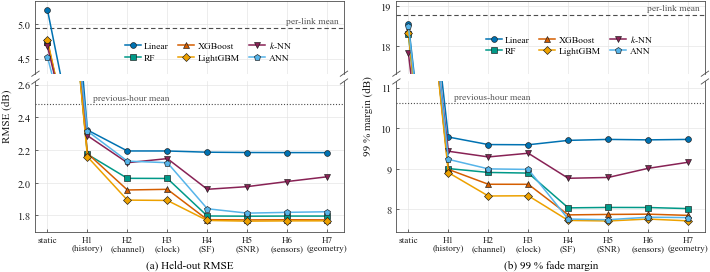

In [3]:
# Figure: hold-out RMSE and 99 % margin against the information rung, one line per family, from the result files of this notebook and notebook 13;
# each y-axis is broken so that the rungs H1 to H7 are readable beside the static rung
import paper_figures as pf
pf.use()
table = pd.read_csv("CV_Results/information_by_family.csv", index_col=[0, 1])
references = pd.read_csv("CV_Results/history_benchmark.csv", index_col=[0, 1])
x = np.arange(len(RUNG_ORDER))
fig = plt.figure(figsize=(pf.PAGE, 2.9))
gs = fig.add_gridspec(2, 2, height_ratios=[1.3, 2.7], hspace=0.07, wspace=0.17, left=0.062, right=0.997, top=0.985, bottom=0.19)
bottoms = []
for col, (metric, top_lim, bottom_lim, ylabel) in enumerate((("hold-out RMSE", (4.28, 5.33), (1.70, 2.62), "RMSE (dB)"),
                                                             ("margin 0.99", (17.3, 19.12), (7.45, 11.15), "99 % margin (dB)"))):
    link_mean, hour_mean = references.loc[("link mean", "-"), metric], references.loc[("previous-hour mean", "-"), metric]
    static = [table.loc[(f, "static"), metric] for f in pf.FAMILIES] + [link_mean]
    history = [table.loc[(f, r), metric] for f in pf.FAMILIES for r in RUNG_ORDER[1:]] + [hour_mean]
    assert top_lim[0] < min(static) and max(static) < top_lim[1] and bottom_lim[0] < min(history) and max(history) < bottom_lim[1]   # nothing clipped
    top = fig.add_subplot(gs[0, col])
    bottom = fig.add_subplot(gs[1, col], sharex=top)
    for ax in (top, bottom):
        for fam in pf.FAMILIES:
            pf.family_line(ax, x, [table.loc[(fam, r), metric] for r in RUNG_ORDER], fam)
        ax.axhline(link_mean, color=pf.INK2, lw=0.8, ls=(0, (4, 2.5)), zorder=1)
        ax.axhline(hour_mean, color=pf.INK2, lw=0.8, ls=(0, (1, 1.6)), zorder=1)
        ax.set_xlim(-0.3, 7.42)
    top.set_ylim(*top_lim)
    bottom.set_ylim(*bottom_lim)
    top.spines["bottom"].set_visible(False)
    bottom.spines["top"].set_visible(False)
    top.tick_params(axis="x", which="both", bottom=False, labelbottom=False)
    bottom.set_xticks(x)
    bottom.set_xticklabels([pf.RUNG_LABEL[r] for r in RUNG_ORDER], fontsize=6.6, linespacing=1.0)
    pf.break_marks(top, bottom)
    top.text(7.3, link_mean + 0.035 * (top_lim[1] - top_lim[0]), "per-link mean", ha="right", va="bottom", fontsize=6.8, color=pf.INK2)
    bottom.text(1.15, hour_mean + 0.012 * (bottom_lim[1] - bottom_lim[0]), "previous-hour mean", ha="left", va="bottom", fontsize=6.8, color=pf.INK2)
    top.legend(handles=pf.family_handles(), ncol=3, loc="center", bbox_to_anchor=(0.56, 0.5 * (link_mean - top_lim[0]) / (top_lim[1] - top_lim[0])),
               fontsize=6.8, handlelength=1.7, columnspacing=1.0, handletextpad=0.35, labelspacing=0.3, borderaxespad=0.0)   # between the break and the per-link mean
    bottom.set_ylabel(ylabel)
    bottom.yaxis.set_label_coords(-0.075, 0.5 * (1 + 0.07 + 1.3 / 2.7))         # centred on the two stacked axes
    bottoms.append(bottom)
pf.subcaptions(fig, bottoms, ["(a) Held-out RMSE", "(b) 99 % fade margin"])
fig.savefig("Figures/information_by_family.png")
plt.show()

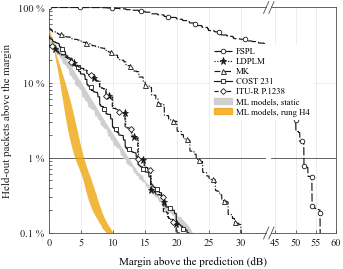

In [2]:
# Figure: the upper tail of the held-out residuals, the share of packets above a margin; the six families as one band without history (notebooks
# 02-07) and one on rung H4 (13 and 14), and the five propagation models of notebook 01. The axis is broken between 34 and 44 dB to show FSPL whole.
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
import paper_figures as pf
pf.use()
grid_db = np.linspace(0, 66, 2641)

def exceedance(name):
    r = np.sort(pd.read_csv(f"Residuals/residuals_{name}_test.csv", usecols=["resid_db"])["resid_db"].to_numpy())
    return 1 - np.searchsorted(r, grid_db, side="right") / len(r)

static_band = np.array([exceedance(STATIC_FILE[f]) for f in FAMILIES])
h4_band = np.array([exceedance(f"{f}_H4") for f in FAMILIES])
PLM = [("PLM_FSPL", "FSPL", (0, (7, 2)), "o", 3.3, 0.0), ("PLM_FIXED_POINT_LDPLM", "LDPLM", (0, (1, 1.3)), "*", 5.2, 0.025),
       ("PLM_MOTLEY_KEENAN", "MK", (0, (5, 1.5, 1, 1.5)), "^", 3.6, 0.05), ("PLM_COST231_MWM", "COST 231", "-", "s", 3.2, 0.075),
       ("PLM_ITU_R_P1238", "ITU-R P.1238", (0, (3.5, 1.8)), "D", 3.0, 0.01)]       # the order of the static models; markers start at staggered points of each curve
plm = {name: exceedance(name) for name, *_ in PLM}
GREY = "#cfcfcf"
fig = plt.figure(figsize=(pf.COLUMN, 2.75))
left = fig.add_axes([0.15, 0.15, 0.62, 0.82])
right = fig.add_axes([0.785, 0.15, 0.185, 0.82], sharey=left)
for ax in (left, right):
    ax.fill_between(grid_db, static_band.min(axis=0), static_band.max(axis=0), color=GREY, lw=0, zorder=2)
    ax.fill_between(grid_db, h4_band.min(axis=0), h4_band.max(axis=0), color=pf.AMBER, alpha=0.75, lw=0, zorder=3)
    for name, _, ls, marker, size, start in PLM:
        ax.plot(grid_db, plm[name], color=pf.INK, lw=0.85, ls=ls, marker=marker, ms=size, mfc=pf.INK if marker == "*" else "white", mec=pf.INK, mew=0.6,
                markevery=(start, 0.1), zorder=4)
    ax.set_yscale("log")
    ax.set_ylim(1e-3, 1)
    ax.axhline(1e-2, color=pf.INK2, lw=0.6, zorder=1)
left.set_xlim(0, 34)
right.set_xlim(44, 60)
left.spines["right"].set_visible(False)
right.spines["left"].set_visible(False)
right.tick_params(axis="y", which="both", left=False, labelleft=False)
left.set_xticks([0, 5, 10, 15, 20, 25, 30])
right.set_xticks([45, 50, 55, 60])
left.set_yticks([1e-3, 1e-2, 1e-1, 1])
left.set_yticklabels(["0.1 %", "1 %", "10 %", "100 %"])
d = 0.012
for ax, x in ((left, 1), (right, 0)):                                           # break marks on the x-axis, at the bottom and the top
    k = left.get_position().width / ax.get_position().width
    for y in (0, 1):
        ax.plot([x - d * k, x + d * k], [y - 2.2 * d, y + 2.2 * d], transform=ax.transAxes, color=pf.INK2, lw=0.6, clip_on=False)
fig.text(0.56, 0.045, "Margin above the prediction (dB)", ha="center", va="center", fontsize=8)
left.set_ylabel("Held-out packets above the margin")
handles = [Line2D([], [], color=pf.INK, lw=0.85, ls=ls, marker=marker, ms=size, mfc=pf.INK if marker == "*" else "white", mec=pf.INK, mew=0.6, label=label)
           for _, label, ls, marker, size, _ in PLM]
handles += [Patch(color=GREY, label="ML models, static"), Patch(color=pf.AMBER, alpha=0.75, label="ML models, rung H4")]
corner = fig.transFigure.inverted().transform(right.transData.transform((54.5, 0.33)))   # the legend's upper-right corner, between MK and FSPL
fig.legend(handles=handles, loc="upper right", bbox_to_anchor=tuple(corner), fontsize=6.3, frameon=True, framealpha=1.0, edgecolor="none", fancybox=False,
           borderpad=0.45, labelspacing=0.22, handlelength=2.1, handletextpad=0.45, borderaxespad=0.0)
fig.savefig("Figures/static_residual_tails.png")
plt.show()

In [5]:
# A link the model has never seen (rung H4), every family: fitted on five links and tested on the sixth, against the same model fitted on the same
# blocks with the link included; the difference is the transfer penalty
unseen = pd.concat([pd.read_csv(f, index_col=[0, 1]) for f in ("CV_Results/history_unseen_link.csv", "CV_Results/history_unseen_link_KNN.csv")])
unseen.index.names = ["family", "link"]
unseen["transfer penalty"] = unseen["RMSE on the unseen link"] - unseen["RMSE with the link in training"]
unseen.to_csv("CV_Results/unseen_link_by_family.csv")
summary = unseen.groupby("family").agg(**{"RMSE with the link in training, mean over links": ("RMSE with the link in training", "mean"),
                                           "RMSE on the unseen link, mean over links": ("RMSE on the unseen link", "mean"),
                                           "worst link": ("RMSE on the unseen link", "max"), "transfer penalty, mean": ("transfer penalty", "mean"),
                                           "transfer penalty, largest": ("transfer penalty", "max"), "reached 0.99, mean over links": ("reached on the unseen link", "mean")}).reindex(FAMILIES)
summary["hold-out RMSE at H4, whole training window"] = [table["hold-out RMSE"].get((f, "H4"), np.nan) for f in FAMILIES]
print(summary.round(3).to_string())
print("\nper link, RMSE on the unseen link (dB)")
print(unseen["RMSE on the unseen link"].unstack("link").reindex(FAMILIES).round(2).to_string())
print("\nper link, transfer penalty (dB)")
print(unseen["transfer penalty"].unstack("link").reindex(FAMILIES).round(2).to_string())

        RMSE with the link in training, mean over links  RMSE on the unseen link, mean over links  worst link  transfer penalty, mean  transfer penalty, largest  reached 0.99, mean over links  hold-out RMSE at H4, whole training window
family                                                                                                                                                                                                                                     
Linear                                            2.188                                     2.192       2.373                   0.005                      0.013                          0.998                                       2.187
RF                                                1.859                                     1.863       2.047                   0.004                      0.009                          0.997                                       1.797
XGB                                               1.827 

In [6]:
# The static models on a link they have never seen: each fitted on the five other links (whole training window, the settings notebooks 02-07
# selected), tested on the sixth link's hold-out; the reference is the same model with the link in training, from its saved hold-out residuals.
# The k-NN rows come from notebook 14 (GPU kernel).
import pickle
from sklearn.base import clone
import tensorflow as tf
from tensorflow import keras
tf.config.set_visible_devices([], "GPU")
STATIC = ["distance", "frequency", "c_walls", "w_walls", "co2", "humidity", "pm25", "pressure", "temperature"]   # the input order of notebooks 02-07
s_train, s_test = pd.read_csv("Data_Files/train.csv"), pd.read_csv("Data_Files/test.csv")
Xtr, ytr, dtr = s_train[STATIC].to_numpy(), s_train["PL"].to_numpy(), s_train["device_id"].to_numpy()
Xte, yte, dte = s_test[STATIC].to_numpy(), s_test["PL"].to_numpy(), s_test["device_id"].to_numpy()
ann_sel = pd.read_csv("CV_Results/ann_tied_selection.csv").iloc[0]                      # the configuration notebook 07 selected

class StaticANN:
    """The network of notebook 07 (dense layers without bias, batch normalization, ReLU; Adam with gradient clipping) in its selected
    configuration, the target standardised inside the fit, three seeds, early stopping on the latest tenth of the training rows."""
    def __init__(self, seeds=(0, 1, 2)):
        self.layers, self.l2, self.dropout, self.lr, self.seeds = json.loads(ann_sel["Hidden Layers"]), float(ann_sel["L2 Reg"]), float(ann_sel["Dropout Rate"]), float(ann_sel["Learning Rate"]), seeds
    def fit(self, X, y):
        self.scaler = StandardScaler().fit(X)
        Xs, y = self.scaler.transform(X).astype(np.float32), y.astype(np.float32)
        n_stop = len(Xs) // 10
        self.y_mean, self.y_sd = float(np.mean(y[:-n_stop])), float(np.std(y[:-n_stop]))    # the target is standardised inside the fit
        ys = (y - self.y_mean) / self.y_sd
        self.nets = []
        for seed in self.seeds:
            tf.keras.utils.set_random_seed(seed)
            net = keras.Sequential([keras.Input(shape=(Xs.shape[1],))])
            for n in self.layers:
                net.add(keras.layers.Dense(n, use_bias=False, kernel_regularizer=keras.regularizers.l2(self.l2)))
                net.add(keras.layers.BatchNormalization())
                net.add(keras.layers.ReLU())
                if self.dropout > 0:
                    net.add(keras.layers.Dropout(self.dropout))
            net.add(keras.layers.Dense(1))
            net.compile(optimizer=keras.optimizers.Adam(self.lr, clipnorm=1.0), loss="mean_squared_error", steps_per_execution=32)
            net.fit(Xs[:-n_stop], ys[:-n_stop], validation_data=(Xs[-n_stop:], ys[-n_stop:]), epochs=300, batch_size=512, verbose=0,
                    callbacks=[keras.callbacks.EarlyStopping(patience=20, restore_best_weights=True), keras.callbacks.ReduceLROnPlateau(factor=0.5, patience=8, min_lr=1e-6)])
            self.nets.append(net)
        return self
    def predict(self, X):
        Xs = self.scaler.transform(X).astype(np.float32)
        return self.y_mean + self.y_sd * np.mean([net.predict(Xs, batch_size=8192, verbose=0).ravel() for net in self.nets], axis=0)

static_models = {"Linear": lambda: clone(pickle.load(open("Models/mlr_final_model.pkl", "rb"))), "RF": lambda: clone(pickle.load(open("Models/rf_final_model.pkl", "rb"))),
                 "XGB": lambda: clone(pickle.load(open("Models/xgb_final_model.pkl", "rb"))), "LGBM": lambda: clone(pickle.load(open("Models/lgbm_final_model.pkl", "rb"))), "ANN": StaticANN}
srows = {}
for fam, make in static_models.items():
    ref = pd.read_csv(f"Residuals/residuals_{STATIC_FILE[fam]}_test.csv", usecols=["device_id", "resid_db"])
    for link in sorted(np.unique(dtr)):
        t0 = time.time()
        fit_m, test_m = dtr != link, dte == link
        e = yte[test_m] - make().fit(Xtr[fit_m], ytr[fit_m]).predict(Xte[test_m])
        srows[(fam, link)] = {"RMSE on the unseen link": rmse(e), "bias on the unseen link": float(-e.mean()),
                              "RMSE with the link in training": rmse(ref.loc[ref["device_id"] == link, "resid_db"].to_numpy())}
        print(f"{LABEL[fam]} without {link}: {srows[(fam, link)]['RMSE on the unseen link']:.2f} dB on the unseen link, "
              f"{srows[(fam, link)]['RMSE with the link in training']:.2f} with it in training ({time.time() - t0:.0f} s)")
static_unseen = pd.concat([pd.DataFrame(srows).T, pd.read_csv("CV_Results/unseen_link_static_KNN.csv", index_col=[0, 1])])
static_unseen.index.names = ["family", "link"]
static_unseen = static_unseen.reindex([(f, l) for f in FAMILIES for l in sorted(np.unique(dtr))])
static_unseen.to_csv("CV_Results/unseen_link_static.csv")
n_link = pd.Series(dte).value_counts()
static_summary = static_unseen.groupby("family").agg(**{"RMSE on the unseen link, mean over links": ("RMSE on the unseen link", "mean"), "worst link": ("RMSE on the unseen link", "max"),
                                                       "RMSE with the link in training, mean over links": ("RMSE with the link in training", "mean")}).reindex(FAMILIES)
static_summary["RMSE on the unseen link, pooled"] = [float(np.sqrt((static_unseen.loc[f, "RMSE on the unseen link"] ** 2 * n_link.reindex(static_unseen.loc[f].index)).sum() / n_link.sum())) for f in FAMILIES]
print(static_summary.round(3).to_string())
print("\nper link, RMSE on the unseen link (dB)")
print(static_unseen["RMSE on the unseen link"].unstack("link").reindex(FAMILIES).round(2).to_string())
print("\nper link, bias on the unseen link, prediction minus measurement (dB)")
print(static_unseen["bias on the unseen link"].unstack("link").reindex(FAMILIES).round(1).to_string())

I0000 00:00:1793017612.421317 3894953 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1793017612.443464 3894953 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1793017613.139683 3894953 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
W0000 00:00:1793017613.451259 3894953 gpu_device.cc:2459] TensorFlow was not built with CUDA kernel binaries compatible with compute capability 12.0a. CUDA kernels will be jit-compiled from PTX, which could take 30 minutes or longer.


Linear without ED0: 6.46 dB on the unseen link, 4.42 with it in training (0 s)


Linear without ED1: 5.36 dB on the unseen link, 4.73 with it in training (0 s)


Linear without ED2: 6.06 dB on the unseen link, 5.08 with it in training (0 s)


...

ANN without ED2: 9.52 dB on the unseen link, 4.99 with it in training (247 s)


ANN without ED3: 12.20 dB on the unseen link, 4.34 with it in training (276 s)


ANN without ED4: 8.90 dB on the unseen link, 3.96 with it in training (371 s)


ANN without ED5: 19.82 dB on the unseen link, 4.10 with it in training (268 s)


        RMSE on the unseen link, mean over links  worst link  RMSE with the link in training, mean over links  RMSE on the unseen link, pooled
family                                                                                                                                        
Linear                                     6.389       8.953                                            5.114                            6.683
RF                                         7.931      20.680                                            4.714                            9.859
XGB                                        9.588      15.568                                            4.727                           10.257
LGBM                                       7.768      13.931                                            4.748                            8.350
KNN                                       10.970      26.722                                            4.637                           13.465

In [7]:
# The history frame of notebooks 13 and 14 for the cells below: rows with a complete history; folds -1 to 4 are the training window, 9 the hold-out
train = pd.read_csv("Data_Files/history_train.csv")
test = pd.read_csv("Data_Files/history_test.csv")
d = pd.concat([train, test], ignore_index=True)
d["t"] = pd.to_datetime(d["t"], utc=True)
d = d.sort_values("t").reset_index(drop=True)
fold = d["fold"].to_numpy()
H = {k.split()[0]: v for k, v in RUNGS.items()}
ok = (d["y"].notna() & d[H["H7"]].notna().all(axis=1)).to_numpy()
cal, ev = ok & (fold >= 0) & (fold < 9), ok & (fold == 9)
y, work = d["y"].to_numpy(), d["work"].to_numpy() == 1
X_all = d[H["H7"]].copy()
X_all = X_all.fillna(X_all[ok & (fold < 9)].median())
best = json.load(open("CV_Results/history_best_params.json"))

In [8]:
# How many links the history model needs: LightGBM on rung H4 fitted on k = 1 to 5 of the other links (folds 0-3, as in the unseen-link test
# above), scored on the held-out link's hold-out; k = 0 is the anchor alone, k = 6 the reference with the link in training on the same blocks.
# At k = 5 the fit is the unseen-link fit of notebook 13.
dev = d["device_id"].to_numpy()
X4 = X_all[H["H4"]].to_numpy()

def lgbm_h4():
    return lgb.LGBMRegressor(subsample_freq=1, random_state=RANDOM_STATE, n_jobs=8, verbose=-1, **best["LGBM"])

fit_all = ok & (fold >= 0) & (fold < 4)
m_all = lgbm_h4().fit(X4[fit_all], y[fit_all])
links = sorted(np.unique(dev))
crows = []
for j, link in enumerate(links):
    test_m = ev & (dev == link)
    crows.append({"held-out link": link, "training links": 0, "which": "anchor alone", "RMSE": rmse(y[test_m])})
    crows.append({"held-out link": link, "training links": 6, "which": "all six, link in training", "RMSE": rmse(y[test_m] - m_all.predict(X4[test_m]))})
    order = [l for l in links if l != link]
    np.random.default_rng(j).shuffle(order)                                    # one nested sequence of training links per held-out link
    for k in range(1, 6):
        t0 = time.time()
        fit_m = fit_all & np.isin(dev, order[:k])
        crows.append({"held-out link": link, "training links": k, "which": "+".join(order[:k]), "RMSE": rmse(y[test_m] - lgbm_h4().fit(X4[fit_m], y[fit_m]).predict(X4[test_m]))})
        print(f"{link} held out, trained on {crows[-1]['which']}: {crows[-1]['RMSE']:.3f} dB ({time.time() - t0:.0f} s)")
curve = pd.DataFrame(crows)
curve.to_csv("CV_Results/links_curve_H4.csv", index=False)
print("\nhold-out RMSE of the held-out link (dB) by number of training links")
print(curve.pivot_table(index="training links", columns="held-out link", values="RMSE").round(3).to_string())
print(curve.groupby("training links")["RMSE"].agg(["mean", "min", "max"]).round(3).to_string())
check = curve[curve["training links"] == 5].set_index("held-out link")["RMSE"] - unseen.loc["LGBM", "RMSE on the unseen link"]
print(f"\nk = 5 against the unseen-link test of notebook 13: largest difference {check.abs().max():.4f} dB")

ED0 held out, trained on ED3: 1.934 dB (8 s)


ED0 held out, trained on ED3+ED5: 1.800 dB (11 s)


ED0 held out, trained on ED3+ED5+ED4: 1.789 dB (15 s)


ED0 held out, trained on ED3+ED5+ED4+ED1: 1.798 dB (17 s)


ED0 held out, trained on ED3+ED5+ED4+ED1+ED2: 1.786 dB (23 s)


...

ED5 held out, trained on ED4: 1.801 dB (8 s)


ED5 held out, trained on ED4+ED3: 1.806 dB (11 s)


ED5 held out, trained on ED4+ED3+ED1: 1.772 dB (14 s)


ED5 held out, trained on ED4+ED3+ED1+ED2: 1.767 dB (18 s)


ED5 held out, trained on ED4+ED3+ED1+ED2+ED0: 1.770 dB (21 s)

hold-out RMSE of the held-out link (dB) by number of training links
held-out link     ED0    ED1    ED2    ED3    ED4    ED5
training links                                          
0               2.464  2.483  2.783  2.168  2.437  2.505
1               1.934  2.008  2.120  1.709  1.790  1.801
2               1.800  1.995  2.036  1.692  1.799  1.806
3               1.789  1.988  2.031  1.695  1.793  1.772
4               1.798  1.985  2.028  1.691  1.798  1.767
5               1.786  1.990  2.019  1.697  1.791  1.770
6               1.787  1.985  2.012  1.691  1.793  1.760
                 mean    min    max
training links                     
0               2.473  2.168  2.783
1               1.894  1.709  2.120
2               1.855  1.692  2.036
3               1.845  1.695  2.031
4               1.844  1.691  2.028
5               1.842  1.697  2.019
6               1.838  1.691  2.012

k = 5 against the unseen-link t

In [9]:
# Margins that follow the state of the link: quantile models on rung H4 (and H6 at 99 %)
def oof_and_test(make, cols):
    X = X_all[cols].to_numpy()
    q = np.full(len(d), np.nan)
    for k in range(5):
        tr, va = ok & (fold < k), ok & (fold == k)
        q[va] = make().fit(X[tr], y[tr]).predict(X[va])
    tr = ok & (fold < 9)
    q[ev] = make().fit(X[tr], y[tr]).predict(X[ev])
    return q

def state_margin(q, rho):
    """The quantile prediction shifted by a constant chosen on the validation folds, so that the margin is calibrated like the fixed one."""
    m = q + shift_pooled((y - q)[cal], rho)
    return {"mean margin": float(m[ev].mean()), "in working hours": float(m[ev & work].mean()), "other hours": float(m[ev & ~work].mean()), "reached": float((y[ev] <= m[ev]).mean())}

qrows = {}
for rho in TARGETS:
    fm = shift_pooled(y[cal], rho)
    qrows[(f"{rho:.2f}", "one fixed margin above the previous-hour mean", "H1")] = {"mean margin": fm, "in working hours": fm, "other hours": fm, "reached": float((y[ev] <= fm).mean())}
quantile_models = {
    "LightGBM": lambda rho: lgb.LGBMRegressor(objective="quantile", alpha=rho, subsample_freq=1, random_state=RANDOM_STATE, n_jobs=8, verbose=-1, **best["LGBM"]),
    "XGBoost": lambda rho: xgb.XGBRegressor(objective="reg:quantileerror", quantile_alpha=rho, device="cuda", tree_method="hist", random_state=RANDOM_STATE, **best["XGB"]),
}
for name, make in quantile_models.items():
    for rung, rhos in (("H4", TARGETS), ("H6", (0.99,))):
        for rho in rhos:
            t0 = time.time()
            qrows[(f"{rho:.2f}", f"{name} quantile model", rung)] = state_margin(oof_and_test(lambda: make(rho), H[rung]), rho)
            print(f"{name} {rung} rho={rho}: {qrows[(f'{rho:.2f}', f'{name} quantile model', rung)]['mean margin']:.2f} dB mean margin ({time.time() - t0:.0f} s)")


LightGBM H4 rho=0.9: 1.89 dB mean margin (191 s)


LightGBM H4 rho=0.95: 2.45 dB mean margin (187 s)


LightGBM H4 rho=0.99: 3.98 dB mean margin (178 s)


LightGBM H6 rho=0.99: 3.97 dB mean margin (204 s)


XGBoost H4 rho=0.9: 1.90 dB mean margin (15 s)


XGBoost H4 rho=0.95: 2.47 dB mean margin (15 s)


XGBoost H4 rho=0.99: 3.98 dB mean margin (14 s)


XGBoost H6 rho=0.99: 3.98 dB mean margin (18 s)


In [10]:
# ANN with the pinball loss at 99 %, rungs H4 and H6 (same network and protocol as notebook 13)
import tensorflow as tf
from tensorflow import keras
tf.config.set_visible_devices([], "GPU")

class ANNQuantile:
    def __init__(self, layers, rho, seeds=(0, 1, 2)):
        self.layers, self.rho, self.seeds, self.scaler, self.nets = layers, rho, seeds, StandardScaler(), []
    def fit(self, X, y):
        Xs = self.scaler.fit_transform(X).astype(np.float32); y = y.astype(np.float32)
        n_val = max(1, len(Xs) // 10)
        rho = self.rho
        pinball = lambda t, q: tf.reduce_mean(tf.maximum(rho * (t - q), (rho - 1) * (t - q)))
        self.nets = []
        for seed in self.seeds:
            tf.keras.utils.set_random_seed(seed)
            net = keras.Sequential([keras.Input(shape=(Xs.shape[1],))] + [keras.layers.Dense(n, activation="relu") for n in self.layers] + [keras.layers.Dense(1)])
            net.compile(optimizer=keras.optimizers.Adam(1e-3), loss=pinball)
            net.fit(Xs[:-n_val], y[:-n_val], validation_data=(Xs[-n_val:], y[-n_val:]), epochs=200, batch_size=2048, verbose=0,
                    callbacks=[keras.callbacks.EarlyStopping(patience=10, restore_best_weights=True), keras.callbacks.ReduceLROnPlateau(factor=0.5, patience=4, min_lr=1e-5)])
            self.nets.append(net)
        return self
    def predict(self, X):
        Xs = self.scaler.transform(X).astype(np.float32)
        return np.mean([net.predict(Xs, batch_size=8192, verbose=0).ravel() for net in self.nets], axis=0)

layers = tuple(best["ANN"])
for rung in ("H4", "H6"):
    t0 = time.time()
    qrows[("0.99", "ANN quantile model", rung)] = state_margin(oof_and_test(lambda: ANNQuantile(layers, 0.99), H[rung]), 0.99)
    print(f"ANN {rung} rho=0.99: {qrows[('0.99', 'ANN quantile model', rung)]['mean margin']:.2f} dB mean margin ({time.time() - t0:.0f} s)")

state = pd.DataFrame(qrows).T
state.index.names = ["target", "model", "rung"]
state.to_csv("CV_Results/state_margins.csv")
print(state.round(3).to_string())


ANN H4 rho=0.99: 3.95 dB mean margin (516 s)


ANN H6 rho=0.99: 3.84 dB mean margin (387 s)
                                                           mean margin  in working hours  other hours  reached
target model                                         rung                                                     
0.90   one fixed margin above the previous-hour mean H1          3.418             3.418        3.418    0.917
0.95   one fixed margin above the previous-hour mean H1          4.837             4.837        4.837    0.970
0.99   one fixed margin above the previous-hour mean H1         10.618            10.618       10.618    0.999
0.90   LightGBM quantile model                       H4          1.895             2.262        1.740    0.900
0.95   LightGBM quantile model                       H4          2.455             3.010        2.221    0.953
0.99   LightGBM quantile model                       H4          3.975             5.159        3.476    0.993
                                                     H6          3.

In [11]:
# Sparser uplinks: every 10th and every 60th packet of each link kept, anchor = mean of the previous 20 kept packets, LightGBM on rung H4.
# The references are compared on the rows where all of them exist.
srows = {}
raw = pd.concat([pd.read_csv("Data_Files/train.csv").assign(fold=np.load("Data_Files/train_folds.npy")), pd.read_csv("Data_Files/test.csv").assign(fold=9)], ignore_index=True)
raw["t"] = pd.to_datetime(raw["time"], utc=True, format="mixed")
raw = raw.drop(columns="time").sort_values(["device_id", "t"])
for k in (10, 60):
    s = build(raw[raw.groupby("device_id").cumcount() % k == 0], anchor="m20")
    s_fold, s_ok = s["fold"].to_numpy(), s["y"].notna().to_numpy()      # windows shorter than the uplink interval are undefined; LightGBM takes them as missing
    s_cal, s_ev = s_ok & (s_fold >= 0) & (s_fold < 9), s_ok & (s_fold == 9)
    Xs, ys = s[H["H4"]].to_numpy(), s["y"].to_numpy()
    q = np.full(len(s), np.nan)
    for f in range(5):
        tr, va = s_ok & (s_fold < f), s_ok & (s_fold == f)
        q[va] = lgb.LGBMRegressor(subsample_freq=1, random_state=RANDOM_STATE, n_jobs=8, verbose=-1, **best["LGBM"]).fit(Xs[tr], ys[tr]).predict(Xs[va])
    tr = s_ok & (s_fold < 9)
    q[s_ev] = lgb.LGBMRegressor(subsample_freq=1, random_state=RANDOM_STATE, n_jobs=8, verbose=-1, **best["LGBM"]).fit(Xs[tr], ys[tr]).predict(Xs[s_ev])
    errors = {"previous kept packet": ys - s["r_lag1"].to_numpy(), "mean of the previous 20 kept packets": ys, "mean of the previous 24 hours": ys - s["r_m24h"].to_numpy(), "LightGBM on rung H4": ys - q}
    have = np.all([~np.isnan(e) for e in errors.values()], axis=0)
    for name, e in errors.items():
        fm = shift_pooled(e[s_cal & have], 0.99)
        srows[(f"every {k} min", name)] = {"hold-out RMSE": rmse(e[s_ev & have]), "margin 0.99": fm, "reached": float((e[s_ev & have] <= fm).mean()), "hold-out rows": int((s_ev & have).sum())}
sparse = pd.DataFrame(srows).T
sparse.index.names = ["uplink interval", "predictor"]
sparse.to_csv("CV_Results/sparse_uplinks.csv")
print(sparse.round(3).to_string())


                                                      hold-out RMSE  margin 0.99  reached  hold-out rows
uplink interval predictor                                                                               
every 10 min    previous kept packet                          3.186       12.000    0.999        53199.0
                mean of the previous 20 kept packets          2.520       11.850    0.998        53199.0
                mean of the previous 24 hours                 3.077       13.078    0.997        53199.0
                LightGBM on rung H4                           2.060       10.258    0.998        53199.0
every 60 min    previous kept packet                          2.921       12.000    0.999         8862.0
                mean of the previous 20 kept packets          3.069       13.150    0.998         8862.0
                mean of the previous 24 hours                 3.072       13.190    0.998         8862.0
                LightGBM on rung H4                    

In [12]:
# The 99 % quantile of the rung-H4 out-of-fold residuals by spreading-factor group, every history family: the margins of the ladder pool
# the SF7-10 and the SF11-12 packets of the validation blocks
sf_train = pd.read_csv("Data_Files/train.csv", usecols=["SF"])["SF"].to_numpy()
rows = []
for fam in FAMILIES:
    o = pd.read_csv(f"Residuals/residuals_{fam}_H4_oof.csv", usecols=["row_id", "resid_db"])
    s, e = sf_train[o["row_id"].to_numpy()], o["resid_db"].to_numpy()
    rows.append({"family": fam, "q99 SF7-10": np.quantile(e[s <= 10], 0.99), "q99 SF11-12": np.quantile(e[s >= 11], 0.99),
                 "q99 all": np.quantile(e, 0.99), "share SF11-12": (s >= 11).mean()})
by_sf = pd.DataFrame(rows).set_index("family")
by_sf.to_csv("CV_Results/margin_by_sf_group_H4.csv")
display(by_sf.round(3))

,q99 SF7-10,q99 SF11-12,q99 all,share SF11-12
family,,,,
Linear,6.146,17.564,9.700,0.26
RF,5.177,14.669,8.040,0.26
XGB,5.036,14.554,7.867,0.26
LGBM,4.992,14.284,7.729,0.26
KNN,5.547,16.082,8.767,0.26
ANN,5.103,14.367,7.763,0.26
